# Tetovo PM2.5 Priority Map (v2: corrected and validated)

This replaces the original `synthetic_pm_map` notebook. It produces the same output the optimizer reads (`candidate_locations_with_pm.csv`, column `predicted_pm`) but fixes the problems found in the original.

**What changed and why**

| Problem in the original | Fix in this notebook |
|---|---|
| Public record may be AQI sub-index scores, not µg/m³ (trained on column `' pm25'`) | Units audit, automatic detection, and the inverse EPA AQI conversion (both breakpoint sets, printed side by side) |
| "Weather" model also used same-day PM10, O3, NO2, SO2, CO as inputs (PM10 is almost collinear with PM2.5) | Weather-only features: temperature range (inversion proxy), wind, pressure change, humidity, heating degrees, rolling windows, circular wind direction, season and weekday |
| Random 80/20 split on daily, autocorrelated data inflates R² | Chronological holdout plus forward-chaining cross-validation; model comparison vs climatology, Ridge, Random Forest (answers "why XGBoost?") |
| Missing weather silently filled with 0 | Days with too little data dropped, short gaps interpolated |
| Candidate-site values normalized with the candidates' own min/max, the grid with the DEM's | One set of normalization constants (city domain, percentile-clipped) used everywhere, so candidate values are samples of the map |
| Candidate elevation from a different DEM than the map | Elevation and slope sampled from the same rasters for grid and candidates |
| Additive fixed µg/m³ terms | Fractional terms of the baseline, as in the paper's Eq. 2 (same coefficients: 0.21, 0.35, 0.21, 0.21, 0.07, 0.11) |
| Baseline from "mean weather" (Jensen gap: 25.0 vs 33.6) | Baseline anchored to the reference station: `base = station long-run mean / spatial factor at the station`; seasons and scenarios scale it by model predictions |
| Per-point GeoPandas distance loops and polygon-buffer joins (very slow) | STRtree nearest-distance and KD-tree building counts, so a 40 m grid takes seconds |
| 250k-point scatter, cubic interpolation, blur | Regular lon/lat grid, no interpolation or smoothing |
| No uncertainty | 1,000-draw perturbation of the 9 free parameters; per-candidate 5th–95th percentile range and **hotspot probability** (saved to the CSV) |
| Validation by a single "nearest candidate" check | Independent check against the sensor.community station: daily correlation **and** the contrast ratio the map predicts vs observes |

**Deviations from the paper's text (update it if you keep these defaults):** the model is weather-only and evaluated chronologically; normalization uses the city domain with 1st–99th percentile clipping; the baseline is station-anchored.

In [ ]:
!pip install -q geopandas rasterio scikit-learn xgboost matplotlib pyproj shapely scipy contextily

In [ ]:
# @title Configuration
BASE_PATH = "/content/drive/MyDrive/Capstone/LoRa Placement/"

# ---- inputs ----
WEATHER_PATH    = "/content/drive/MyDrive/ML Learning/tetovo_hourly_weather.csv"
PM_PATH         = "/content/drive/MyDrive/ML Learning/MOEPP/cleaned_tetovo_air_quality.csv"
DEM_PATH        = BASE_PATH + "AP_01806_FBS_F0820_RT1/AP_01806_FBS_F0820_RT1/AP_01806_FBS_F0820_RT1_reprojected.dem.tif"
SLOPE_PATH      = BASE_PATH + "viz/viz.hh_slope.tif"
ROADS_PATH      = BASE_PATH + "roads.geojson"
INDUSTRIAL_PATH = BASE_PATH + "industrial_areas.geojson"
BUILDINGS_PATH  = BASE_PATH + "tetovo_buildings.geojson"
FOLIAGE_PATH    = BASE_PATH + "foliage.geojson"
CANDIDATES_PATH = BASE_PATH + "candidate_locations_with_elevation.csv"
COMMUNITY_GLOB  = BASE_PATH + "sensor_community/*.csv"     # optional: sensor.community exports (station 80372)
COMMUNITY_LATLON = 41.997591, 20.965183                                     # e.g. (42.0, 20.95) if the CSVs have no lat/lon columns
OUT_CSV         = BASE_PATH + "candidate_locations_with_pm.csv"

# ---- units ----
PM_IS_AQI = None               # None = auto-detect; True/False to force
AQI_BREAKPOINTS = "epa_2012"   # "epa_2012" or "epa_2024"; choose the one whose mean matches your reference (33.6 in the paper)

# ---- model ----
TEST_FRACTION = 0.2            # last 20% of days = untouched chronological holdout
N_SPLITS = 5                   # forward-chaining CV folds on the training part
MIN_HOURS_PER_DAY = 18
MODEL_CHOICE = "xgboost"       # "xgboost", "random_forest", "ridge", or "auto" (lowest CV RMSE)

# ---- study area / grid ----
MOEPP_LAT, MOEPP_LON = 42.0053889, 20.9687778
CITY_BBOX = (20.927753, 41.969382, 21.008091, 42.033166)    # lon_min, lat_min, lon_max, lat_max
GRID_RES_M = 40
DENSITY_RADIUS_M = 500

# ---- spatial model (paper Eq. 2) ----
ALPHA  = dict(road=0.21, ind=0.35, dens=0.21, elev=0.21, slope=0.07, fol=0.11)
LAMBDA = dict(road=500.0, ind=1000.0, fol=300.0)
AMPLITUDE_SCALE = 1.0          # multiplies all six terms; keep 1.0 for the paper's model
ROBUST_NORM = True             # 1st-99th percentile over the city domain instead of min-max
ANCHOR_TO_STATION = True       # baseline = station long-run mean / spatial factor at the station
CANDIDATE_ELEV_SOURCE = "raster"   # "raster" = same DEM as the map (recommended); "csv" = FABDEM column

# ---- priority / robustness ----
HOTSPOT_QUANTILE = 0.75
N_DRAWS = 1000
PERTURB = 0.5                  # each parameter scaled by U(1-0.5, 1+0.5)
RNG_SEED = 42

In [ ]:
# @title Imports and helpers
import os, glob, json, shutil, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from shapely.geometry import box
from shapely import STRtree
from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr, rankdata
from pyproj import Transformer
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as mpatches
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

plt.rcParams.update({"font.size": 14, "axes.labelsize": 16, "axes.titlesize": 16,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13})

def savefig(name):
    plt.savefig(BASE_PATH + name + ".png", dpi=300, bbox_inches="tight")
    plt.savefig(BASE_PATH + name + ".pdf", bbox_inches="tight")

# ---------- EPA AQI -> concentration (PM2.5), piecewise linear inverse ----------
AQI_TABLES = {
    "epa_2012": [(0, 50, 0.0, 12.0), (51, 100, 12.1, 35.4), (101, 150, 35.5, 55.4), (151, 200, 55.5, 150.4),
                 (201, 300, 150.5, 250.4), (301, 400, 250.5, 350.4), (401, 500, 350.5, 500.4)],
    "epa_2024": [(0, 50, 0.0, 9.0), (51, 100, 9.1, 35.4), (101, 150, 35.5, 55.4), (151, 200, 55.5, 125.4),
                 (201, 300, 125.5, 225.4), (301, 500, 225.5, 325.4)],
}

def aqi_to_pm25(aqi, table):
    aqi = np.asarray(aqi, dtype=float)
    out = np.full(aqi.shape, np.nan)
    for k, (ilo, ihi, clo, chi) in enumerate(table):
        upper = table[k + 1][0] if k + 1 < len(table) else np.inf
        m = (aqi >= ilo) & (aqi < upper)
        out[m] = clo + (aqi[m] - ilo) * (chi - clo) / (ihi - ilo)
    out[aqi > table[-1][1]] = table[-1][3]
    return out

# ---------- fast geometry helpers ----------
def nearest_dist(x, y, gdf_layer):
    g = gdf_layer[gdf_layer.geometry.notna() & ~gdf_layer.geometry.is_empty]
    tree = STRtree(list(g.geometry))
    pts = shapely.points(np.asarray(x, float), np.asarray(y, float))
    idx, dist = tree.query_nearest(pts, return_distance=True, all_matches=False)
    d = np.full(len(pts), np.nan)
    d[idx[0]] = dist
    return d

def sample_raster(path, x, y, xy_crs):
    with rasterio.open(path) as src:
        if src.crs is not None and xy_crs is not None and src.crs != xy_crs:
            xs, ys = Transformer.from_crs(xy_crs, src.crs, always_xy=True).transform(np.asarray(x), np.asarray(y))
        else:
            xs, ys = np.asarray(x), np.asarray(y)
        vals = np.array([v[0] for v in src.sample(list(zip(xs, ys)))], dtype=float)
        nod = src.nodata
    if nod is not None:
        vals[vals == nod] = np.nan
    vals[~np.isfinite(vals)] = np.nan
    return vals

print("Helpers ready.")

Mounted at /content/drive
Helpers ready.


In [ ]:
# @title Load weather and PM2.5, units audit
# ---------- daily weather features (weather-only; no co-pollutants) ----------
w = pd.read_csv(WEATHER_PATH)
w = w.rename(columns={"time": "date"})
w["date"] = pd.to_datetime(w["date"])
w = w.set_index("date").sort_index()
for c in ["temp", "dwpt", "rhum", "prcp", "snow", "wdir", "wspd", "wpgt", "pres", "tsun"]:
    if c not in w.columns:
        w[c] = np.nan
rad = np.deg2rad(w["wdir"])
w["_ws"], w["_wc"] = np.sin(rad), np.cos(rad)       # circular mean of wind direction
g = w.resample("D")
daily = pd.DataFrame({
    "temp": g["temp"].mean(), "temp_min": g["temp"].min(), "temp_max": g["temp"].max(),
    "dwpt": g["dwpt"].mean(), "rhum": g["rhum"].mean(),
    "prcp": g["prcp"].sum(min_count=1), "snow": g["snow"].max(),
    "wspd": g["wspd"].mean(), "wpgt": g["wpgt"].max(), "pres": g["pres"].mean(),
    "tsun": g["tsun"].sum(min_count=1),
    "wdir_sin": g["_ws"].mean(), "wdir_cos": g["_wc"].mean(),
    "n_hours": g["temp"].count(),
})
daily = daily[daily["n_hours"] >= MIN_HOURS_PER_DAY].drop(columns="n_hours")

# drop features that are mostly missing, fill the rest conservatively
miss = daily.isna().mean()
drop_cols = miss[miss > 0.30].index.tolist()
if drop_cols:
    print("Dropping weather features with >30% missing:", drop_cols)
daily = daily.drop(columns=drop_cols)
for c in ["prcp", "snow"]:
    if c in daily.columns:
        daily[c] = daily[c].fillna(0.0)
daily = daily.interpolate(limit=3, limit_area="inside")

daily["dtr"] = daily["temp_max"] - daily["temp_min"]                  # diurnal range = inversion proxy
daily["hdd"] = (15.0 - daily["temp"]).clip(lower=0)                   # heating degrees
daily["temp_roll3"] = daily["temp"].rolling(3, min_periods=1).mean()
daily["wspd_roll3"] = daily["wspd"].rolling(3, min_periods=1).mean()
if "prcp" in daily.columns:
    daily["prcp_roll3"] = daily["prcp"].rolling(3, min_periods=1).sum()
daily["dpres"] = daily["pres"].diff()                                 # synoptic change
doy = daily.index.dayofyear.values
daily["doy_sin"], daily["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
daily["is_weekend"] = (daily.index.dayofweek >= 5).astype(float)
daily["month"] = daily.index.month

# ---------- PM record and units audit ----------
pm_raw = pd.read_csv(PM_PATH)
pm_raw.columns = pm_raw.columns.str.strip().str.lower()
pm_raw["date"] = pd.to_datetime(pm_raw["date"]).dt.normalize()
pm_raw = pm_raw.sort_values("date")

share = float((pm_raw["pm25"] > pm_raw["pm10"]).mean()) if "pm10" in pm_raw.columns else np.nan
auto_aqi = bool(share > 0.5) if not np.isnan(share) else False
IS_AQI = auto_aqi if PM_IS_AQI is None else bool(PM_IS_AQI)

print("=== UNITS AUDIT ===")
print(f"PM2.5 > PM10 on {100 * share:.1f}% of days (impossible for true concentrations; expected for AQI sub-index scores)")
print(f"Treating the record as: {'AQI sub-index scores (converting)' if IS_AQI else 'concentrations in ug/m3 (no conversion)'}")
print(f"Raw PM2.5 mean: {pm_raw['pm25'].mean():.2f}")
if IS_AQI:
    for name, tbl in AQI_TABLES.items():
        print(f"  mean after {name} conversion: {np.nanmean(aqi_to_pm25(pm_raw['pm25'].values, tbl)):.2f} ug/m3")
    pm_raw["pm25_ugm3"] = aqi_to_pm25(pm_raw["pm25"].values, AQI_TABLES[AQI_BREAKPOINTS])
    print(f"Using {AQI_BREAKPOINTS}")
else:
    pm_raw["pm25_ugm3"] = pm_raw["pm25"].astype(float)

pm_series = pm_raw.groupby("date")["pm25_ugm3"].mean().dropna()
PM_STATION_OBS = float(pm_series.mean())
print(f"Reference-station long-run mean PM2.5: {PM_STATION_OBS:.2f} ug/m3 over {len(pm_series)} days "
      f"({PM_STATION_OBS / 5.0:.1f}x the WHO annual guideline of 5)")

FEATURES = [c for c in ["temp", "temp_min", "temp_max", "dtr", "hdd", "dwpt", "rhum", "prcp", "snow", "wspd", "wpgt",
                        "pres", "dpres", "tsun", "wdir_sin", "wdir_cos", "temp_roll3", "wspd_roll3", "prcp_roll3",
                        "doy_sin", "doy_cos", "is_weekend"] if c in daily.columns]
data = daily.join(pm_series.rename("pm25_ugm3"), how="inner").dropna(subset=FEATURES + ["pm25_ugm3"]).sort_index()
print(f"\nModelling set: {len(data)} days, {data.index.min().date()} to {data.index.max().date()}, {len(FEATURES)} weather/calendar features")
print("Features:", FEATURES)

Dropping weather features with >30% missing: ['prcp', 'snow', 'tsun']
=== UNITS AUDIT ===
PM2.5 > PM10 on 71.3% of days (impossible for true concentrations; expected for AQI sub-index scores)
Treating the record as: AQI sub-index scores (converting)
Raw PM2.5 mean: 91.16
  mean after epa_2012 conversion: 35.36 ug/m3
  mean after epa_2024 conversion: 32.47 ug/m3
Using epa_2012
Reference-station long-run mean PM2.5: 35.36 ug/m3 over 2574 days (7.1x the WHO annual guideline of 5)

Modelling set: 1970 days, 2019-03-07 to 2025-04-08, 18 weather/calendar features
Features: ['temp', 'temp_min', 'temp_max', 'dtr', 'hdd', 'dwpt', 'rhum', 'wspd', 'wpgt', 'pres', 'dpres', 'wdir_sin', 'wdir_cos', 'temp_roll3', 'wspd_roll3', 'doy_sin', 'doy_cos', 'is_weekend']


In [ ]:
# @title Weather model: comparison, chronological evaluation, final model
n = len(data)
cut = int(n * (1 - TEST_FRACTION))
X_tr, y_tr = data.iloc[:cut][FEATURES + ["month"]], data.iloc[:cut]["pm25_ugm3"]
X_te, y_te = data.iloc[cut:][FEATURES + ["month"]], data.iloc[cut:]["pm25_ugm3"]
tscv = TimeSeriesSplit(n_splits=N_SPLITS)
print(f"Train: {len(X_tr)} days (to {X_tr.index.max().date()}) | Holdout: {len(X_te)} days (from {X_te.index.min().date()})")

def scores(y_true, y_pred):
    return dict(R2=r2_score(y_true, y_pred), RMSE=float(np.sqrt(mean_squared_error(y_true, y_pred))),
                MAE=mean_absolute_error(y_true, y_pred))

class MonthClimatology:
    def fit(self, X, y):
        self.m_ = y.groupby(X["month"]).mean()
        self.g_ = float(y.mean())
        return self
    def predict(self, X):
        return X["month"].map(self.m_).fillna(self.g_).values

# ---- tune XGBoost on the training part only (forward-chaining CV) ----
grid = {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.06], "n_estimators": [200, 400], "min_child_weight": [3, 8]}
base_xgb = xgb.XGBRegressor(objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
                            random_state=42, n_jobs=1)
gs = GridSearchCV(base_xgb, grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_tr[FEATURES], y_tr)
BEST_XGB = gs.best_params_
print("Best XGBoost params:", BEST_XGB)

def make_xgb():
    return xgb.XGBRegressor(objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
                            random_state=42, n_jobs=-1, **BEST_XGB)

MODELS = {
    "Climatology (month mean)": (MonthClimatology, ["month"]),
    "Ridge": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))), FEATURES),
    "Random Forest": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42), FEATURES),
    "XGBoost (tuned)": (make_xgb, FEATURES),
}

rows = []
for name, (factory, cols) in MODELS.items():
    cv = []
    for tr, te in tscv.split(X_tr):
        m = factory().fit(X_tr.iloc[tr][cols], y_tr.iloc[tr])
        cv.append(scores(y_tr.iloc[te], m.predict(X_tr.iloc[te][cols])))
    cv = pd.DataFrame(cv)
    m = factory().fit(X_tr[cols], y_tr)
    ho = scores(y_te, m.predict(X_te[cols]))
    rows.append({"Model": name,
                 "CV R2": f"{cv['R2'].mean():.2f} +/- {cv['R2'].std():.2f}",
                 "CV RMSE": f"{cv['RMSE'].mean():.1f} +/- {cv['RMSE'].std():.1f}",
                 "CV RMSE (num)": cv["RMSE"].mean(),
                 "Holdout R2": round(ho["R2"], 3), "Holdout RMSE": round(ho["RMSE"], 2), "Holdout MAE": round(ho["MAE"], 2)})
model_table = pd.DataFrame(rows).set_index("Model")
display(model_table.drop(columns="CV RMSE (num)"))
print("(CV = forward-chaining on the training part; Holdout = last chronological block, never used for tuning.)")

# ---- choose and fit the final model on all days ----
choice = {"xgboost": "XGBoost (tuned)", "random_forest": "Random Forest", "ridge": "Ridge"}
if MODEL_CHOICE == "auto":
    cand_names = ["Ridge", "Random Forest", "XGBoost (tuned)"]
    CHOSEN = min(cand_names, key=lambda k: model_table.loc[k, "CV RMSE (num)"])
else:
    CHOSEN = choice[MODEL_CHOICE]
print("Final model:", CHOSEN)
factory, cols = MODELS[CHOSEN]
final_model = factory().fit(data[cols], data["pm25_ugm3"])
data["pred"] = final_model.predict(data[cols])

# holdout predictions from the train-only version of the chosen model, for the figure
m_ho = factory().fit(X_tr[cols], y_tr)
ho_pred = pd.Series(m_ho.predict(X_te[cols]), index=X_te.index)
HOLDOUT = scores(y_te, ho_pred.values)
print(f"Chosen model, chronological holdout: R2 = {HOLDOUT['R2']:.3f}, RMSE = {HOLDOUT['RMSE']:.2f} ug/m3, MAE = {HOLDOUT['MAE']:.2f}")

Train: 1576 days (to 2024-03-07) | Holdout: 394 days (from 2024-03-08)
Best XGBoost params: {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 3, 'n_estimators': 200}


,CV R2,CV RMSE,Holdout R2,Holdout RMSE,Holdout MAE
Model,,,,,
Climatology (month mean),0.38 +/- 0.22,22.2 +/- 8.4,0.513,16.60,11.12
Ridge,0.48 +/- 0.29,18.9 +/- 2.3,0.472,17.30,13.75
Random Forest,0.65 +/- 0.08,16.6 +/- 5.1,0.657,13.94,9.34
XGBoost (tuned),0.66 +/- 0.10,16.0 +/- 4.7,0.709,12.84,8.61


(CV = forward-chaining on the training part; Holdout = last chronological block, never used for tuning.)
Final model: XGBoost (tuned)
Chosen model, chronological holdout: R2 = 0.709, RMSE = 12.84 ug/m3, MAE = 8.61


,Model baseline (ug/m3),Observed mean (ug/m3),Scale vs annual,Days
Annual,32.95,33.01,1.00,1970
Winter (Dec-Feb),59.76,60.14,1.81,514
Spring (Mar-May),21.66,21.93,0.66,523
Summer (Jun-Aug),14.54,14.05,0.44,451
Autumn (Sep-Nov),33.84,33.83,1.03,482
Winter stagnation (calm and cold),64.67,64.64,1.96,76


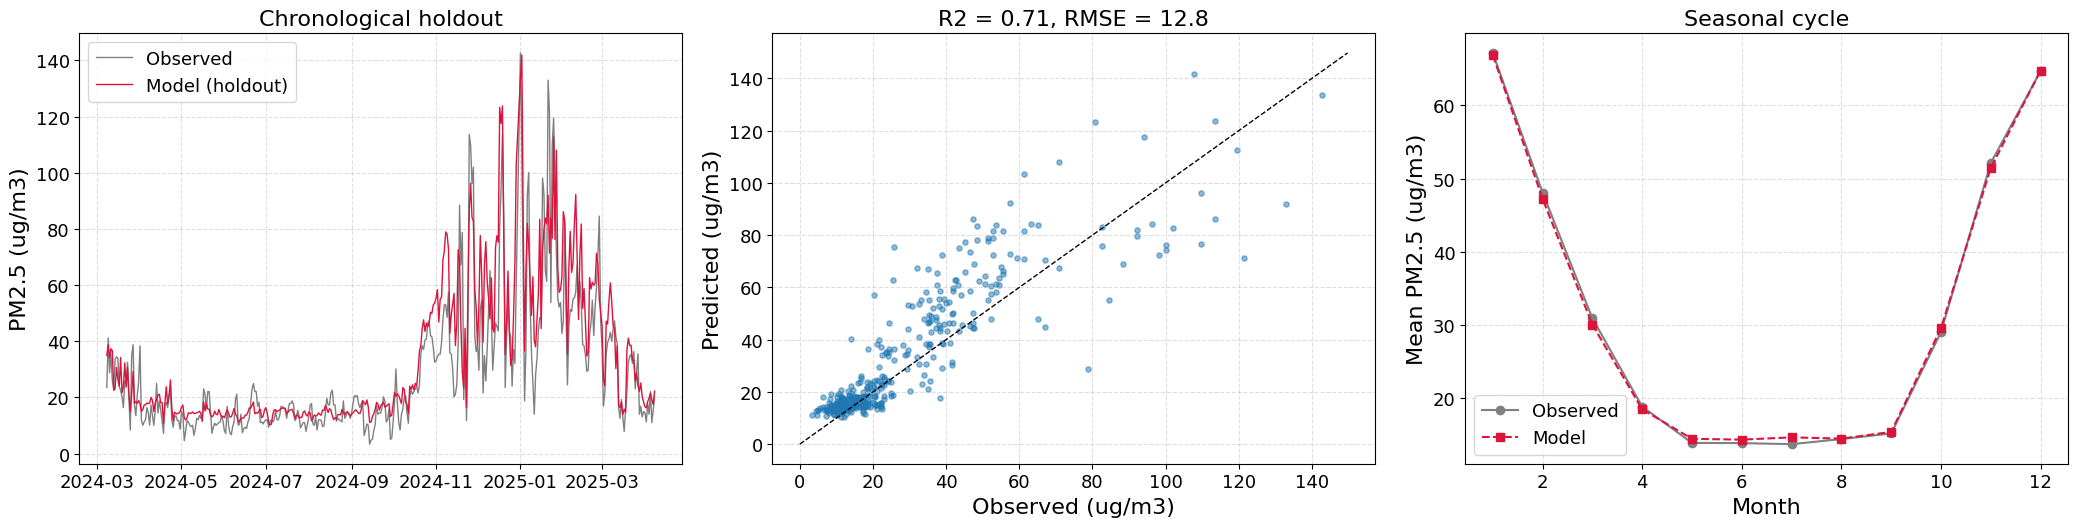

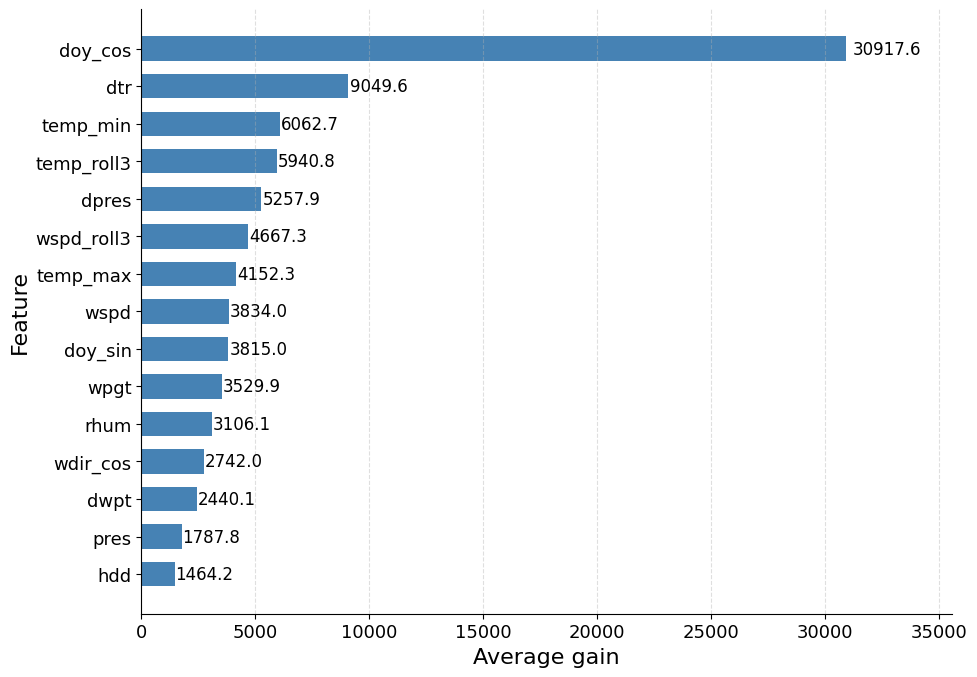

In [ ]:
# @title Seasonal and scenario baselines, model figures
seasons = {"Winter (Dec-Feb)": [12, 1, 2], "Spring (Mar-May)": [3, 4, 5],
           "Summer (Jun-Aug)": [6, 7, 8], "Autumn (Sep-Nov)": [9, 10, 11]}

BASELINES = {"Annual": float(data["pred"].mean())}
OBSERVED = {"Annual": float(data["pm25_ugm3"].mean())}
for name, months in seasons.items():
    mask = data["month"].isin(months)
    BASELINES[name] = float(data.loc[mask, "pred"].mean())
    OBSERVED[name] = float(data.loc[mask, "pm25_ugm3"].mean())
win = data["month"].isin([12, 1, 2])
episode = win & (data["wspd"] <= data.loc[win, "wspd"].quantile(0.25)) & (data["temp"] <= data.loc[win, "temp"].median())
SCEN = "Winter stagnation (calm and cold)"
BASELINES[SCEN] = float(data.loc[episode, "pred"].mean())
OBSERVED[SCEN] = float(data.loc[episode, "pm25_ugm3"].mean())
SCALE = {k: v / BASELINES["Annual"] for k, v in BASELINES.items()}

bt = pd.DataFrame({"Model baseline (ug/m3)": BASELINES, "Observed mean (ug/m3)": OBSERVED, "Scale vs annual": SCALE}).round(2)
bt["Days"] = [len(data)] + [int(data["month"].isin(m).sum()) for m in seasons.values()] + [int(episode.sum())]
display(bt)

# ---------- figures ----------
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
ax = axes[0]
ax.plot(y_te.index, y_te.values, color="gray", lw=1, label="Observed")
ax.plot(ho_pred.index, ho_pred.values, color="crimson", lw=1, label="Model (holdout)")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Chronological holdout"); ax.legend(); ax.grid(True, ls="--", alpha=0.4)
ax = axes[1]
ax.scatter(y_te.values, ho_pred.values, s=14, alpha=0.5)
lim = [0, max(y_te.max(), ho_pred.max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("Observed (ug/m3)"); ax.set_ylabel("Predicted (ug/m3)")
ax.set_title(f"R2 = {HOLDOUT['R2']:.2f}, RMSE = {HOLDOUT['RMSE']:.1f}"); ax.grid(True, ls="--", alpha=0.4)
ax = axes[2]
mo = data.groupby("month")[["pm25_ugm3", "pred"]].mean()
ax.plot(mo.index, mo["pm25_ugm3"], "o-", color="gray", label="Observed")
ax.plot(mo.index, mo["pred"], "s--", color="crimson", label="Model")
ax.set_xlabel("Month"); ax.set_ylabel("Mean PM2.5 (ug/m3)"); ax.set_title("Seasonal cycle"); ax.legend(); ax.grid(True, ls="--", alpha=0.4)
plt.tight_layout(); savefig("pm_model_evaluation"); plt.show()

if hasattr(final_model, "get_booster"):
    sc = final_model.get_booster().get_score(importance_type="gain")
    items = sorted(sc.items(), key=lambda kv: kv[1])[-15:]
    fig, ax = plt.subplots(figsize=(10, 7))
    bars = ax.barh([k for k, _ in items], [v for _, v in items], color="steelblue", height=0.65)
    for b, (_, v) in zip(bars, items):
        ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", fontsize=12)
    ax.set_xlabel("Average gain"); ax.set_ylabel("Feature"); ax.set_xlim(0, max(v for _, v in items) * 1.15)
    ax.grid(True, axis="x", ls="--", alpha=0.4); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); savefig("pm_feature_importance"); plt.show()

In [ ]:
# @title Geospatial layers, grid, spatial features
with rasterio.open(DEM_PATH) as src:
    dem_bounds, dem_crs = src.bounds, src.crs
aoi_geo = gpd.GeoSeries([box(*dem_bounds)], crs=dem_crs)
UTM = aoi_geo.estimate_utm_crs()
aoi_utm = aoi_geo.to_crs(UTM).iloc[0]
print("Projected CRS:", UTM)

def load_layer(path):
    gdf = gpd.read_file(path)
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326")
    return gdf.to_crs(UTM)

roads, industrial, buildings, foliage = [load_layer(p) for p in (ROADS_PATH, INDUSTRIAL_PATH, BUILDINGS_PATH, FOLIAGE_PATH)]
print(f"roads {len(roads)}, industrial {len(industrial)}, buildings {len(buildings)}, foliage {len(foliage)}")

bc = buildings.geometry.centroid
BLD_TREE = cKDTree(np.c_[bc.x.values, bc.y.values])
to_utm = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)

def raw_features(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    elev = sample_raster(DEM_PATH, x, y, UTM)
    elev[elev <= 0] = np.nan                                   # DEM artifacts
    slope = sample_raster(SLOPE_PATH, x, y, UTM)
    slope[slope < 0] = np.nan
    return {"d_road": nearest_dist(x, y, roads), "d_ind": nearest_dist(x, y, industrial),
            "d_fol": nearest_dist(x, y, foliage),
            "dens": BLD_TREE.query_ball_point(np.c_[x, y], r=DENSITY_RADIUS_M, return_length=True).astype(float),
            "elev": elev, "slope": slope}

# ---------- regular lon/lat grid over the city ----------
lon_min, lat_min, lon_max, lat_max = CITY_BBOX
LAT0 = 0.5 * (lat_min + lat_max)
dlat = GRID_RES_M / 110574.0
dlon = GRID_RES_M / (111320.0 * np.cos(np.deg2rad(LAT0)))
lon_v = np.arange(lon_min, lon_max + dlon, dlon)
lat_v = np.arange(lat_min, lat_max + dlat, dlat)
LON_G, LAT_G = np.meshgrid(lon_v, lat_v)
GRID_SHAPE = LON_G.shape
xg, yg = to_utm.transform(LON_G.ravel(), LAT_G.ravel())
INSIDE = shapely.contains_xy(aoi_utm, xg, yg)
print(f"Grid {GRID_SHAPE[1]} x {GRID_SHAPE[0]} at ~{GRID_RES_M} m, {int(INSIDE.sum())} points inside the DEM extent")

RAW_G = raw_features(xg[INSIDE], yg[INSIDE])
print("Grid features computed.")

# ---------- one set of normalization constants for everything ----------
def _range(a):
    a = a[np.isfinite(a)]
    return (np.percentile(a, 1), np.percentile(a, 99)) if ROBUST_NORM else (a.min(), a.max())

NORMS = {"elev": _range(RAW_G["elev"]), "slope": _range(RAW_G["slope"]),
         "dens": (0.0, (np.percentile(RAW_G["dens"], 99) if ROBUST_NORM else RAW_G["dens"].max()))}
def _nz(v, lo, hi):
    return np.clip((v - lo) / (hi - lo + 1e-9), 0.0, 1.0)
FILL = {k: float(np.nanmedian(_nz(RAW_G[k], *NORMS[k]))) for k in NORMS}
print("Normalization ranges:", {k: tuple(round(float(x), 2) for x in v) for k, v in NORMS.items()})

def normalise(raw):
    fn = {"d_road": raw["d_road"], "d_ind": raw["d_ind"], "d_fol": raw["d_fol"]}
    for k in NORMS:
        z = _nz(raw[k], *NORMS[k])
        fn[k] = np.where(np.isnan(z), FILL[k], z)
    return fn

PARAM_NAMES = ["a_road", "a_ind", "a_dens", "a_elev", "a_slope", "a_fol", "l_road", "l_ind", "l_fol"]
BASE_VEC = np.array([ALPHA["road"], ALPHA["ind"], ALPHA["dens"], ALPHA["elev"], ALPHA["slope"], ALPHA["fol"],
                     LAMBDA["road"], LAMBDA["ind"], LAMBDA["fol"]])

def terms_from(fn, vec=BASE_VEC, scale=AMPLITUDE_SCALE):
    a_road, a_ind, a_dens, a_elev, a_slope, a_fol, l_road, l_ind, l_fol = vec
    return {"road": scale * a_road * np.exp(-fn["d_road"] / l_road),
            "industrial": scale * a_ind * np.exp(-fn["d_ind"] / l_ind),
            "density": scale * a_dens * fn["dens"],
            "elevation": -scale * a_elev * fn["elev"],
            "slope": -scale * a_slope * fn["slope"],
            "foliage": -scale * a_fol * np.exp(-fn["d_fol"] / l_fol)}

def factor_from(fn, vec=BASE_VEC):
    t = terms_from(fn, vec)
    return np.clip(1.0 + sum(t.values()), 0.0, None)

FN_G = normalise(RAW_G)

# ---------- reference station ----------
sx, sy = to_utm.transform([MOEPP_LON], [MOEPP_LAT])
RAW_S = raw_features(sx, sy)
FN_S = normalise(RAW_S)
F_STATION = float(factor_from(FN_S)[0])
BASE_ANNUAL = PM_STATION_OBS / F_STATION if ANCHOR_TO_STATION else BASELINES["Annual"]
print(f"Spatial factor at the MOEPP station: {F_STATION:.3f}")
print(f"Annual baseline used for the map: {BASE_ANNUAL:.2f} ug/m3 "
      f"({'station-anchored' if ANCHOR_TO_STATION else 'model mean'}); station long-run mean = {PM_STATION_OBS:.2f}")

Projected CRS: EPSG:32634
roads 248, industrial 21, buildings 13114, foliage 13
Grid 168 x 178 at ~40 m, 29904 points inside the DEM extent
Grid features computed.
Normalization ranges: {'elev': (474.0, 1166.97), 'slope': (0.17, 32.93), 'dens': (0.0, 1085.0)}
Spatial factor at the MOEPP station: 1.544
Annual baseline used for the map: 22.91 ug/m3 (station-anchored); station long-run mean = 35.36


In [ ]:
# @title Candidate sites and the PM2.5 surface
cand = pd.read_csv(CANDIDATES_PATH)
cand["id"] = cand["id"].astype(str)
cx, cy = to_utm.transform(cand["longitude"].values, cand["latitude"].values)
RAW_C = raw_features(cx, cy)
if CANDIDATE_ELEV_SOURCE == "csv":
    RAW_C["elev"] = cand["elevation"].values.astype(float)
    print("WARNING: candidate elevation from the CSV (FABDEM) is normalized with DEM-raster constants; results are not on the same scale as the map.")
FN_C = normalise(RAW_C)

TERMS_C = terms_from(FN_C)
FACTOR_C = factor_from(FN_C)
PM_C = BASE_ANNUAL * FACTOR_C

TERMS_G = terms_from(FN_G)
FACTOR_G = factor_from(FN_G)
PM_G = np.full(GRID_SHAPE[0] * GRID_SHAPE[1], np.nan)
PM_G[INSIDE] = BASE_ANNUAL * FACTOR_G
PM_GRID = PM_G.reshape(GRID_SHAPE)

print(f"Candidates: n = {len(cand)}")
print(f"Predicted PM2.5 over candidates: min {PM_C.min():.1f}, mean {PM_C.mean():.1f}, max {PM_C.max():.1f} ug/m3 "
      f"(max/min = {PM_C.max() / PM_C.min():.2f}, CV = {PM_C.std() / PM_C.mean():.3f})")
print(f"Predicted PM2.5 over the city grid: p5 {np.nanpercentile(PM_GRID, 5):.1f}, p95 {np.nanpercentile(PM_GRID, 95):.1f} ug/m3")
n_nan = {k: int(np.isnan(RAW_C[k]).sum()) for k in ["elev", "slope"]}
print("Candidates with missing raster values (filled with the domain median):", n_nan)

Candidates: n = 99
Predicted PM2.5 over candidates: min 23.8, mean 34.1, max 39.2 ug/m3 (max/min = 1.65, CV = 0.085)
Predicted PM2.5 over the city grid: p5 19.6, p95 35.6 ug/m3
Candidates with missing raster values (filled with the domain median): {'elev': 0, 'slope': 1}


,rho candidates x0.5,rho grid x0.5,rho candidates x1.5,rho grid x1.5,min rho
parameter,,,,,
a_ind,0.913,0.989,0.960,0.994,0.913
a_dens,0.958,0.995,0.961,0.997,0.958
l_ind,0.965,0.995,0.978,0.999,0.965
a_fol,0.985,0.995,0.992,0.996,0.985
a_road,0.989,0.990,0.993,0.994,0.989
l_road,0.990,0.997,0.996,0.999,0.990
l_fol,0.993,0.999,0.996,1.000,0.993
a_elev,0.999,0.994,1.000,0.996,0.994
a_slope,0.999,0.999,0.999,0.999,0.999



=== 1,000-draw joint perturbation (each parameter x U(0.5, 1.5)) ===
Candidate ranking: median rho = 0.965, min = 0.768, 5th percentile = 0.860
City-grid ranking: median rho = 0.991, min = 0.952, 5th percentile = 0.973
Hotspot candidates (top 25%): 25; remain hotspots in >=90% of draws: 15; in >=50%: 23
Most influential parameter (lowest rho): a_ind


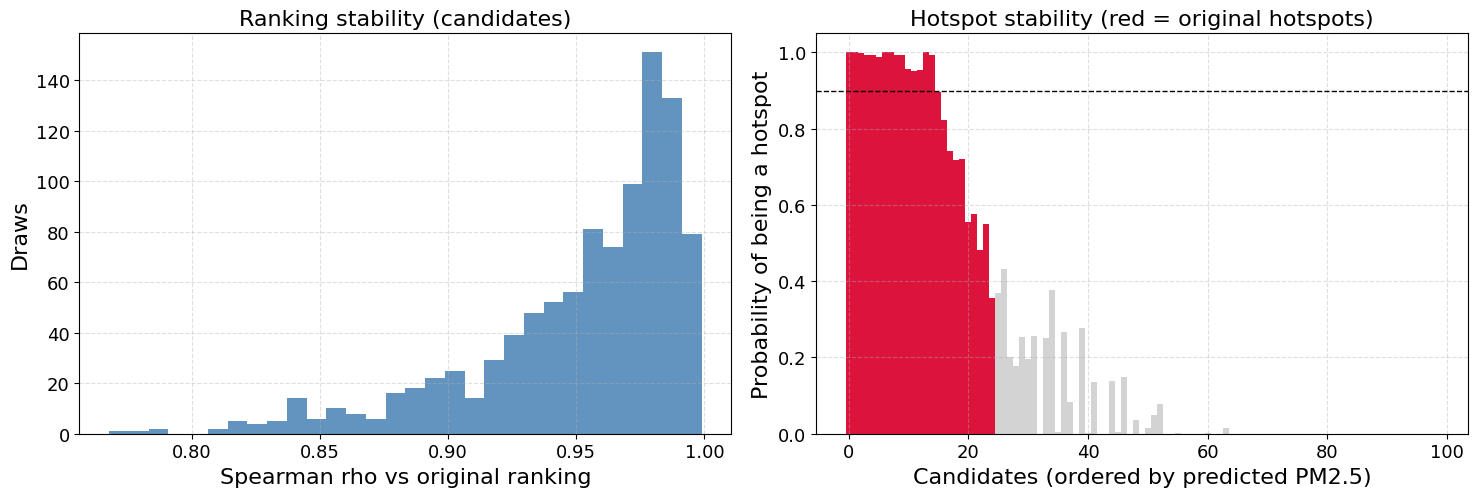

In [ ]:
# @title Parameter robustness: one-at-a-time and 1,000 joint draws
rng = np.random.default_rng(RNG_SEED)

def pm_candidates(vec):
    f_c = factor_from(FN_C, vec)
    base = (PM_STATION_OBS / float(factor_from(FN_S, vec)[0])) if ANCHOR_TO_STATION else BASELINES["Annual"]
    return base * f_c

sub = rng.choice(len(FACTOR_G), size=min(5000, len(FACTOR_G)), replace=False)
FN_G_SUB = {k: v[sub] for k, v in FN_G.items()}
def rho(a, b):
    return float(np.corrcoef(rankdata(a), rankdata(b))[0, 1])

pm0 = pm_candidates(BASE_VEC)
f0_sub = factor_from(FN_G_SUB, BASE_VEC)
q0 = np.quantile(pm0, HOTSPOT_QUANTILE)
hot0 = pm0 >= q0

# ---- one at a time ----
oat = []
for i, name in enumerate(PARAM_NAMES):
    row = {"parameter": name}
    for lab, mult in (("x0.5", 1 - PERTURB), ("x1.5", 1 + PERTURB)):
        v = BASE_VEC.copy(); v[i] *= mult
        row[f"rho candidates {lab}"] = round(rho(pm0, pm_candidates(v)), 3)
        row[f"rho grid {lab}"] = round(rho(f0_sub, factor_from(FN_G_SUB, v)), 3)
    row["min rho"] = min(row[k] for k in row if k.startswith("rho"))
    oat.append(row)
oat_df = pd.DataFrame(oat).sort_values("min rho").set_index("parameter")
display(oat_df)

# ---- all nine at once ----
mult = rng.uniform(1 - PERTURB, 1 + PERTURB, size=(N_DRAWS, len(BASE_VEC)))
rho_c = np.zeros(N_DRAWS); rho_g = np.zeros(N_DRAWS)
hot_count = np.zeros(len(cand)); pm_draws = np.zeros((N_DRAWS, len(cand)))
for d in range(N_DRAWS):
    v = BASE_VEC * mult[d]
    p = pm_candidates(v)
    pm_draws[d] = p
    rho_c[d] = rho(pm0, p)
    rho_g[d] = rho(f0_sub, factor_from(FN_G_SUB, v))
    hot_count += (p >= np.quantile(p, HOTSPOT_QUANTILE))
HOT_PROB = hot_count / N_DRAWS
PM_P05, PM_P95 = np.percentile(pm_draws, 5, axis=0), np.percentile(pm_draws, 95, axis=0)

print("\n=== 1,000-draw joint perturbation (each parameter x U(0.5, 1.5)) ===")
print(f"Candidate ranking: median rho = {np.median(rho_c):.3f}, min = {rho_c.min():.3f}, 5th percentile = {np.percentile(rho_c, 5):.3f}")
print(f"City-grid ranking: median rho = {np.median(rho_g):.3f}, min = {rho_g.min():.3f}, 5th percentile = {np.percentile(rho_g, 5):.3f}")
stable = hot0 & (HOT_PROB >= 0.90)
print(f"Hotspot candidates (top {int((1 - HOTSPOT_QUANTILE) * 100)}%): {int(hot0.sum())}; "
      f"remain hotspots in >=90% of draws: {int(stable.sum())}; in >=50%: {int((hot0 & (HOT_PROB >= 0.5)).sum())}")
print(f"Most influential parameter (lowest rho): {oat_df.index[0]}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].hist(rho_c, bins=30, color="steelblue", alpha=0.85)
axes[0].set_xlabel("Spearman rho vs original ranking"); axes[0].set_ylabel("Draws"); axes[0].set_title("Ranking stability (candidates)")
axes[0].grid(True, ls="--", alpha=0.4)
order = np.argsort(-pm0)
axes[1].bar(range(len(order)), HOT_PROB[order], color=["crimson" if hot0[i] else "lightgray" for i in order], width=1.0)
axes[1].axhline(0.9, color="k", ls="--", lw=1)
axes[1].set_xlabel("Candidates (ordered by predicted PM2.5)"); axes[1].set_ylabel("Probability of being a hotspot")
axes[1].set_title("Hotspot stability (red = original hotspots)"); axes[1].grid(True, ls="--", alpha=0.4)
plt.tight_layout(); savefig("pm_parameter_robustness"); plt.show()

In [ ]:
# @title Independent validation: sensor.community (optional)
COMMUNITY = {}
files = sorted(glob.glob(COMMUNITY_GLOB))
if not files:
    print(f"No community-sensor files matched {COMMUNITY_GLOB}; skipping. Put the sensor.community CSV exports there to run this check.")
else:
    parts = []
    for f in files:
        try:
            d = pd.read_csv(f, sep=";")
            if "P2" not in d.columns:
                d = pd.read_csv(f)
            parts.append(d)
        except Exception as e:
            print("Skipped", os.path.basename(f), "-", e)
    cs = pd.concat(parts, ignore_index=True)
    cs["timestamp"] = pd.to_datetime(cs["timestamp"], errors="coerce", utc=True).dt.tz_localize(None)
    cs["P2"] = pd.to_numeric(cs["P2"], errors="coerce")
    cs = cs.dropna(subset=["timestamp", "P2"])
    cs = cs[(cs["P2"] >= 0) & (cs["P2"] < 1000)]
    d_cs = cs.set_index("timestamp")["P2"].resample("D").agg(["mean", "count"])
    d_cs = d_cs[d_cs["count"] >= 100]["mean"]
    d_cs.index = d_cs.index.normalize()
    both = d_cs.index.intersection(pm_series.index)
    a, b = d_cs.loc[both].values, pm_series.loc[both].values
    r_p, r_s = pearsonr(a, b)[0], spearmanr(a, b)[0]
    ratio_obs = float(a.mean() / b.mean())
    COMMUNITY.update({"n_days": int(len(both)), "pearson_r": float(r_p), "spearman_rho": float(r_s),
                      "mean_community": float(a.mean()), "mean_moepp_same_days": float(b.mean()), "observed_ratio": ratio_obs})
    print(f"Overlapping days: {len(both)}")
    print(f"Daily correlation with the corrected MOEPP record: Pearson r = {r_p:.3f}, Spearman rho = {r_s:.3f}")
    print(f"Mean community sensor {a.mean():.1f} vs MOEPP {b.mean():.1f} ug/m3 on the same days (ratio {ratio_obs:.2f})")

    if COMMUNITY_LATLON is not None:
        lat_s, lon_s = COMMUNITY_LATLON
    elif {"lat", "lon"}.issubset(cs.columns):
        lat_s, lon_s = float(pd.to_numeric(cs["lat"], errors="coerce").median()), float(pd.to_numeric(cs["lon"], errors="coerce").median())
    else:
        lat_s = lon_s = None
    if lat_s is not None:
        ux, uy = to_utm.transform([lon_s], [lat_s])
        fn_cs = normalise(raw_features(ux, uy))
        f_cs = float(factor_from(fn_cs)[0])
        ratio_map = f_cs / F_STATION
        t_cs, t_st = sum(terms_from(fn_cs).values())[0] * 1.0, sum(terms_from(FN_S).values())[0] * 1.0
        COMMUNITY.update({"lat": lat_s, "lon": lon_s, "map_ratio": ratio_map})
        print(f"Sensor location ({lat_s:.5f}, {lon_s:.5f}); map-predicted ratio sensor/station = {ratio_map:.2f} vs observed {ratio_obs:.2f}")
        denom = t_cs - ratio_obs * t_st
        if abs(denom) > 1e-9:
            kappa = (ratio_obs - 1.0) / denom
            COMMUNITY["amplitude_scale_to_match_contrast"] = float(kappa)
            print(f"Diagnostic only: matching this one contrast would need AMPLITUDE_SCALE of about {kappa:.1f} (1 = paper's model).")
        print("Caveat: one low-cost optical sensor is a directional check, not a calibration; humidity bias is not corrected here.")

    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.scatter(b, a, s=18, alpha=0.6)
    lim = [0, max(a.max(), b.max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("MOEPP PM2.5, corrected (ug/m3)"); ax.set_ylabel("Community sensor PM2.5 (ug/m3)")
    ax.set_title(f"Daily means, r = {r_p:.2f} (n = {len(both)})"); ax.grid(True, ls="--", alpha=0.4)
    plt.tight_layout(); savefig("pm_community_validation"); plt.show()

No community-sensor files matched /content/drive/MyDrive/Capstone/LoRa Placement/sensor_community/*.csv; skipping. Put the sensor.community CSV exports there to run this check.


In [ ]:
# @title Sanity checks on the candidate priorities
dem_elev = RAW_C["elev"]
ok = np.isfinite(dem_elev)
pr, pp = pearsonr(dem_elev[ok], PM_C[ok]); sr, sp = spearmanr(dem_elev[ok], PM_C[ok])
print(f"Elevation vs predicted PM2.5: Pearson r = {pr:.3f} (p = {pp:.1e}), Spearman rho = {sr:.3f} (p = {sp:.1e})")
lo_e, hi_e = np.nanpercentile(dem_elev, 20), np.nanpercentile(dem_elev, 80)
print(f"Valley (lowest 20% elevation) mean PM2.5: {PM_C[dem_elev <= lo_e].mean():.1f} | hillside (highest 20%): {PM_C[dem_elev >= hi_e].mean():.1f}")

near_road = FN_C["d_road"] <= 200
print(f"Candidates within 200 m of a mapped road: {100 * near_road.mean():.0f}%")
ctrl = pd.DataFrame({name: [spearmanr(t, PM_C)[0]] for name, t in TERMS_C.items()}, index=["Spearman rho with predicted PM2.5"]).T
display(ctrl.round(3).sort_values("Spearman rho with predicted PM2.5", ascending=False))
print("(The term with the highest |rho| controls the candidate ranking.)")

near = int(np.argmin(np.hypot(RAW_C["d_road"] * 0, 0) + np.hypot(cx - sx[0], cy - sy[0])))
print(f"Candidate nearest the MOEPP station (id {cand.loc[near, 'id']}, "
      f"{np.hypot(cx[near] - sx[0], cy[near] - sy[0]):.0f} m away): predicted {PM_C[near]:.1f} vs station mean {PM_STATION_OBS:.1f} ug/m3")
if ANCHOR_TO_STATION:
    print("Note: with station anchoring this is a consistency check on the spatial factor, not an independent test.")

Elevation vs predicted PM2.5: Pearson r = -0.746 (p = 7.6e-19), Spearman rho = -0.136 (p = 1.8e-01)
Valley (lowest 20% elevation) mean PM2.5: 33.7 | hillside (highest 20%): 30.7
Candidates within 200 m of a mapped road: 89%


,Spearman rho with predicted PM2.5
foliage,0.555
industrial,0.508
density,0.483
road,0.385
slope,0.238
elevation,0.136


(The term with the highest |rho| controls the candidate ranking.)
Candidate nearest the MOEPP station (id 57, 80 m away): predicted 34.7 vs station mean 35.4 ug/m3
Note: with station anchoring this is a consistency check on the spatial factor, not an independent test.


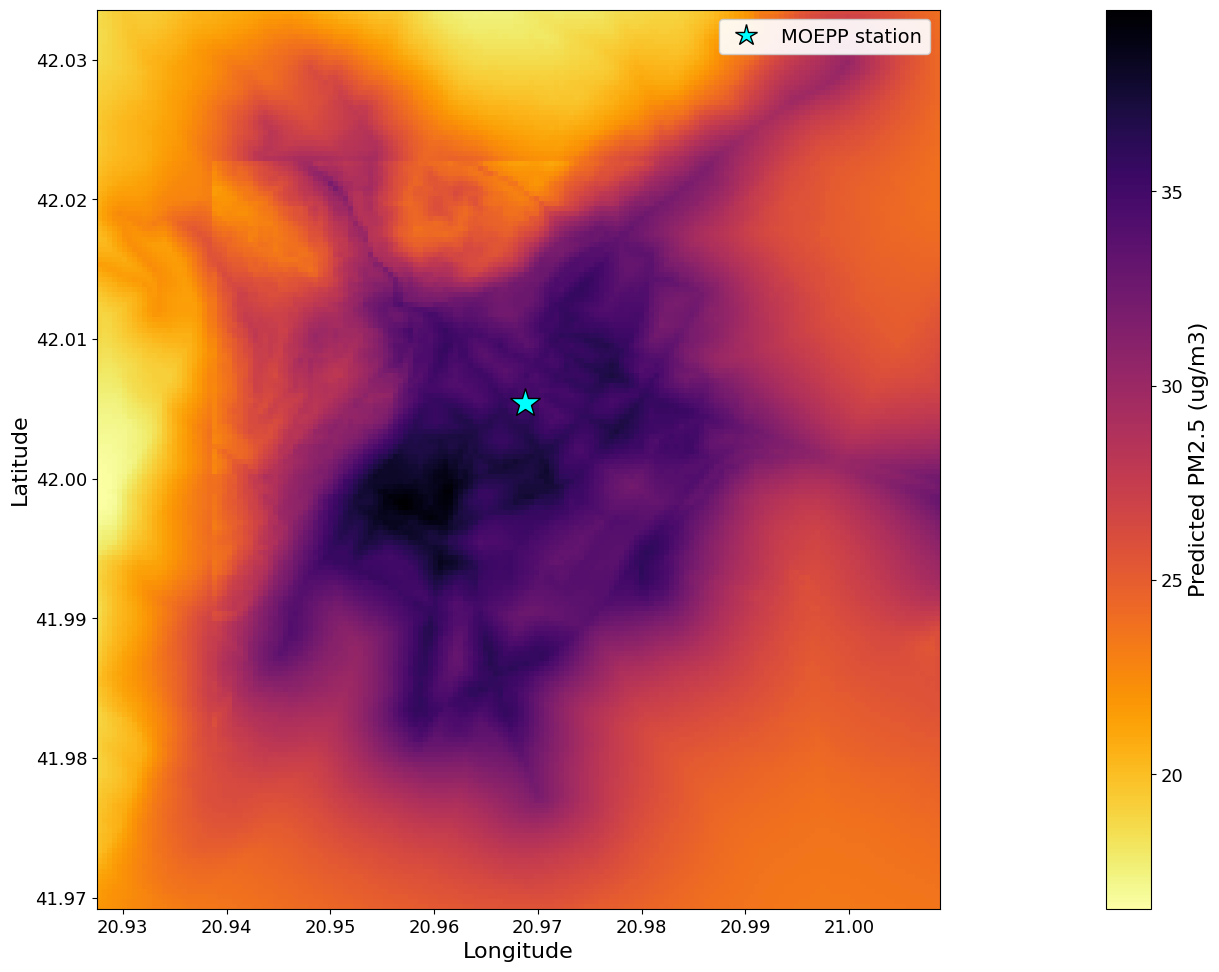

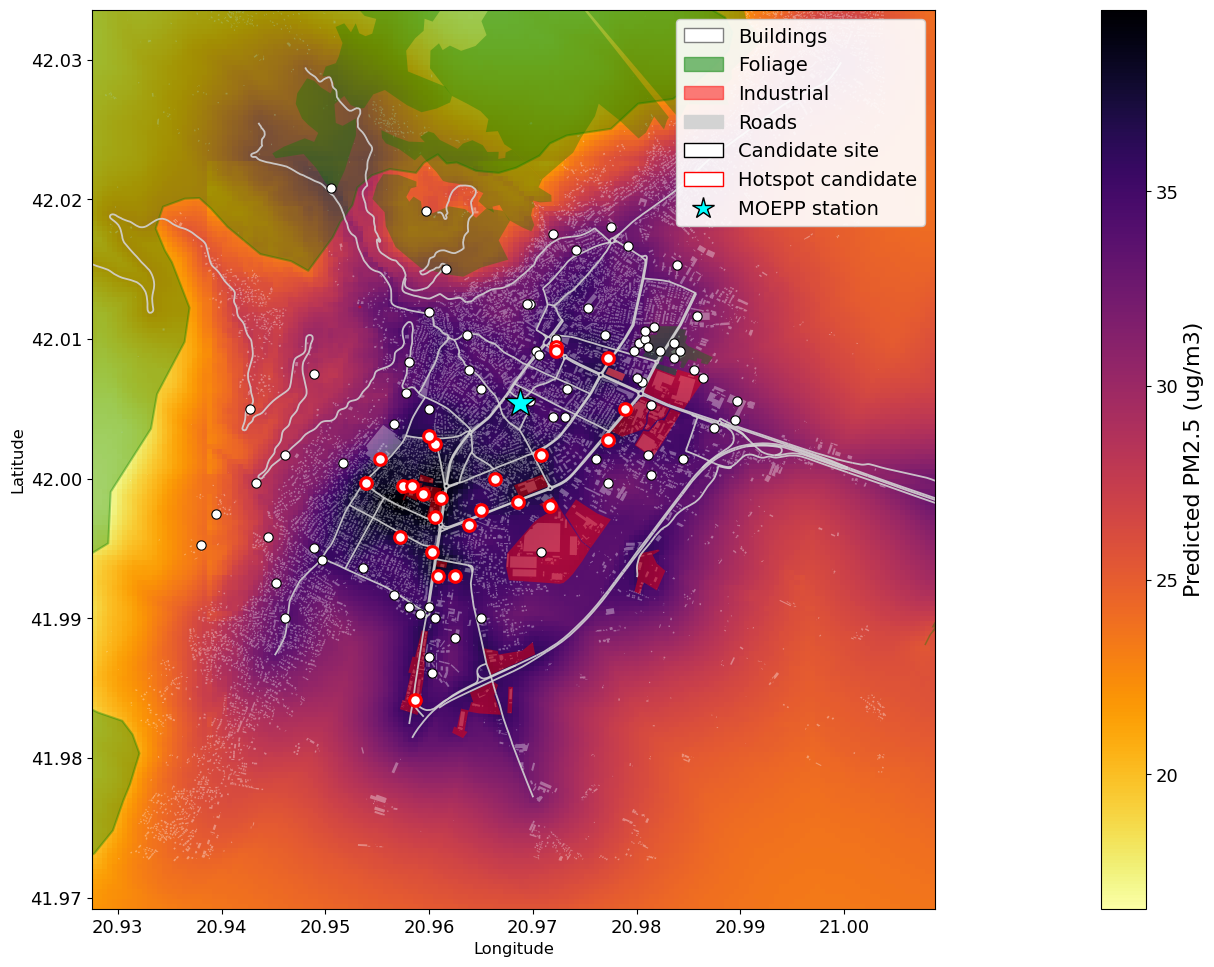

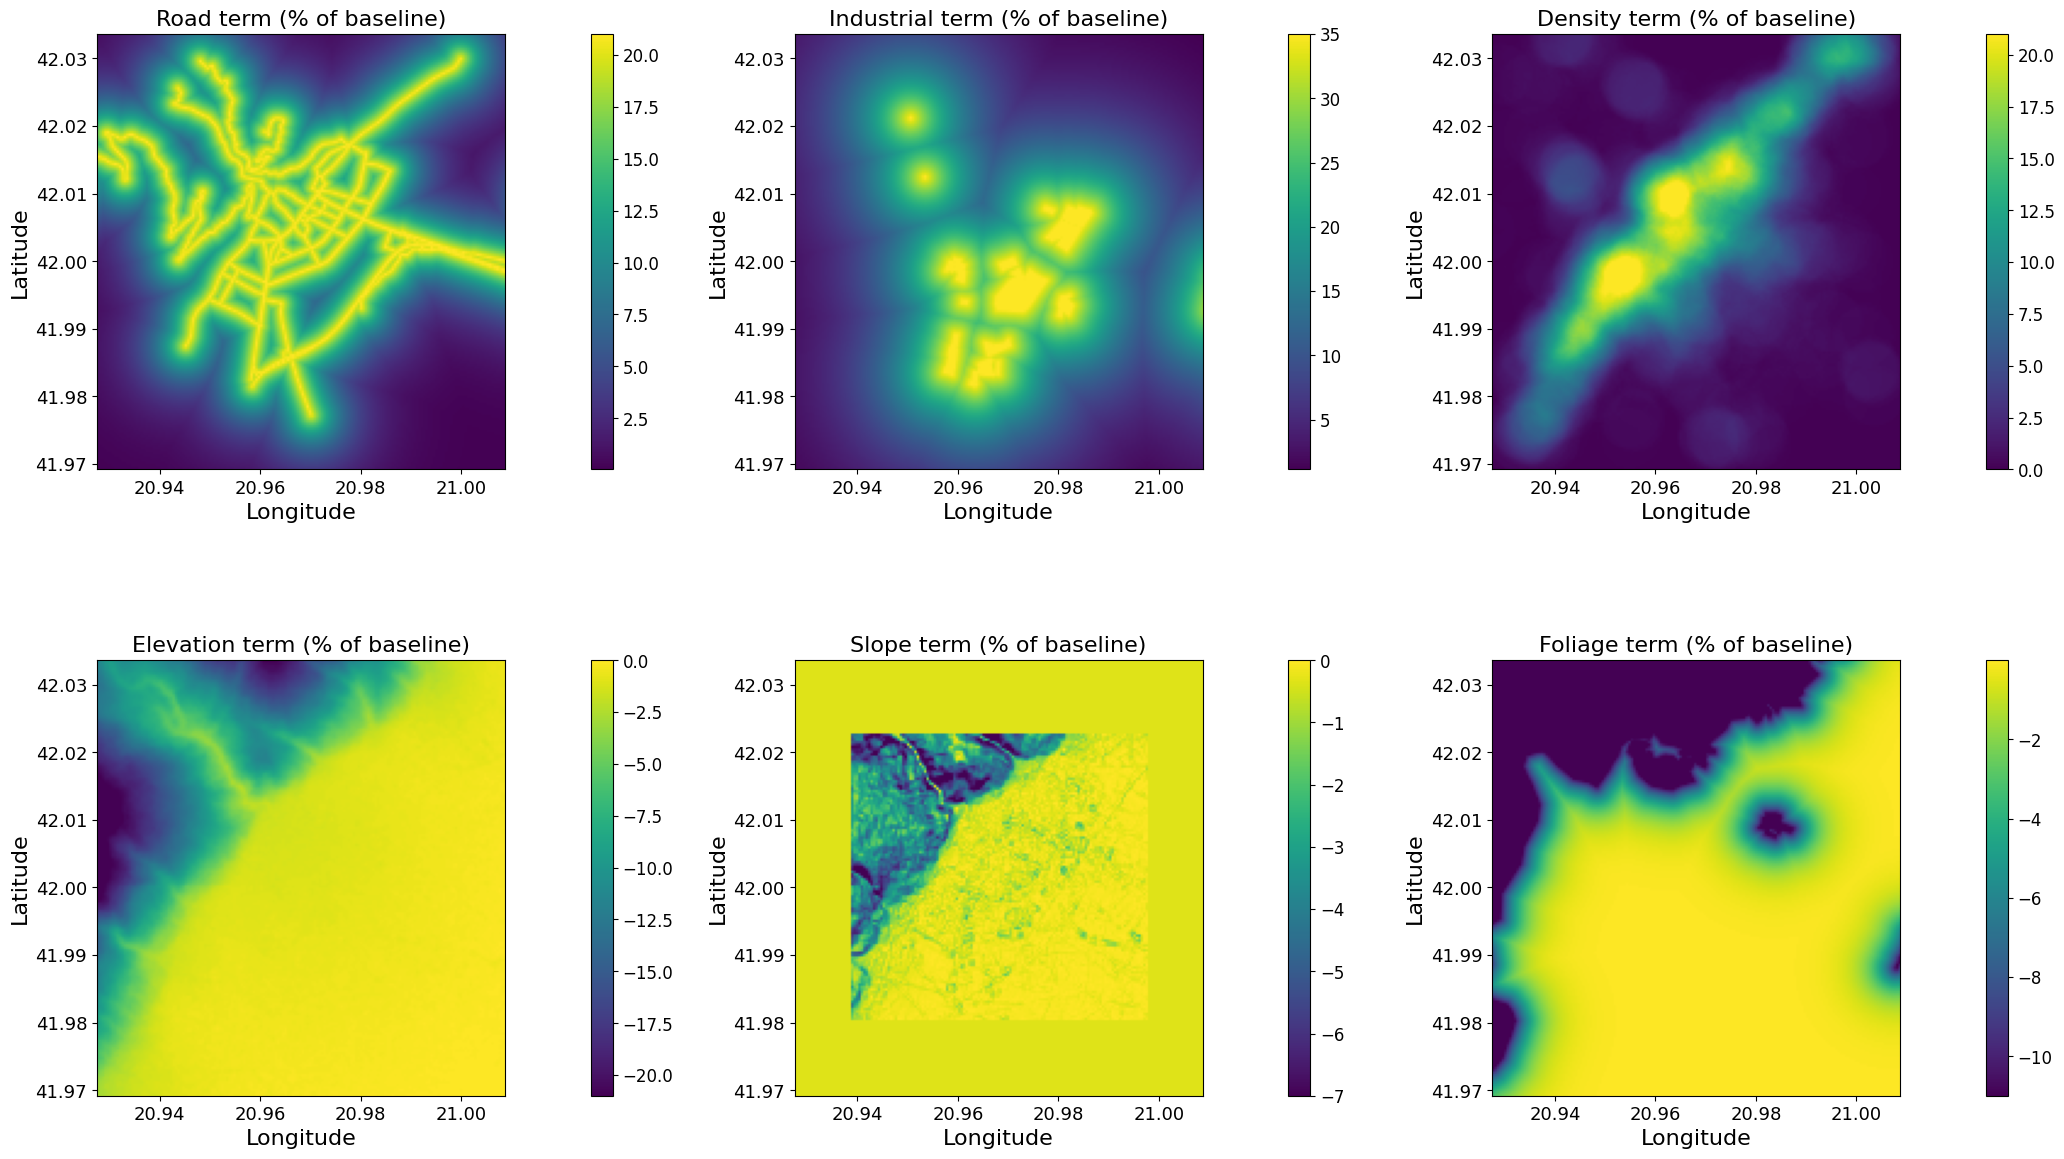

In [ ]:
# @title Figures: PM2.5 surface and per-term panels
roads_ll, ind_ll, fol_ll, bld_ll = [g_.to_crs("EPSG:4326") for g_ in (roads, industrial, foliage, buildings)]
HOT = PM_C >= np.quantile(PM_C, HOTSPOT_QUANTILE)
extent = (lon_v[0] - dlon / 2, lon_v[-1] + dlon / 2, lat_v[0] - dlat / 2, lat_v[-1] + dlat / 2)
ASPECT = 1.0 / np.cos(np.deg2rad(LAT0))

def plot_surface(overlays, fname, show_candidates=True):
    fig, ax = plt.subplots(figsize=(13, 12))
    ax.set_facecolor("#d9d9d9")
    im = ax.imshow(PM_GRID, extent=extent, origin="lower", cmap="inferno_r", aspect=ASPECT)
    handles = []
    if "buildings" in overlays:
        bld_ll.plot(ax=ax, facecolor="white", edgecolor="none", alpha=0.35); handles.append(mpatches.Patch(facecolor="white", edgecolor="gray", label="Buildings"))
    if "foliage" in overlays:
        fol_ll.plot(ax=ax, color="green", alpha=0.35); handles.append(mpatches.Patch(color="green", alpha=0.5, label="Foliage"))
    if "industrial" in overlays:
        ind_ll.plot(ax=ax, color="red", alpha=0.45); handles.append(mpatches.Patch(color="red", alpha=0.5, label="Industrial"))
    if "roads" in overlays:
        roads_ll.plot(ax=ax, color="lightgray", linewidth=1.3, alpha=0.9); handles.append(mpatches.Patch(color="lightgray", label="Roads"))
    if show_candidates:
        ax.scatter(cand["longitude"][~HOT], cand["latitude"][~HOT], s=45, c="white", edgecolors="black", linewidths=0.8, zorder=6)
        ax.scatter(cand["longitude"][HOT], cand["latitude"][HOT], s=70, c="white", edgecolors="red", linewidths=2.2, zorder=7)
        handles += [mpatches.Patch(facecolor="white", edgecolor="black", label="Candidate site"),
                    mpatches.Patch(facecolor="white", edgecolor="red", label="Hotspot candidate")]
    ax.plot(MOEPP_LON, MOEPP_LAT, marker="*", color="cyan", markeredgecolor="black", markersize=22, zorder=8, linestyle="")
    handles.append(plt.Line2D([0], [0], marker="*", color="cyan", markeredgecolor="black", markersize=16, linestyle="", label="MOEPP station"))
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3]); ax.set_aspect(ASPECT)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.2)
    cb = plt.colorbar(im, cax=cax); cb.set_label("Predicted PM2.5 (ug/m3)", fontsize=16); cb.ax.tick_params(labelsize=13)
    ax.legend(handles=handles, loc="upper right", fontsize=14, framealpha=0.92)
    plt.tight_layout(); savefig(fname); plt.show()

plot_surface([], "pm_map_clean", show_candidates=False)
plot_surface(["buildings", "foliage", "industrial", "roads"], "pm_map_all_features")

# ---------- per-term panels (percent of baseline) ----------
fig, axes = plt.subplots(2, 3, figsize=(21, 13))
for ax, (name, t) in zip(axes.ravel(), TERMS_G.items()):
    arr = np.full(GRID_SHAPE[0] * GRID_SHAPE[1], np.nan); arr[INSIDE] = 100 * t
    im = ax.imshow(arr.reshape(GRID_SHAPE), extent=extent, origin="lower", cmap="viridis", aspect=ASPECT)
    ax.set_title(f"{name.capitalize()} term (% of baseline)"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.15)
    plt.colorbar(im, cax=cax).ax.tick_params(labelsize=12)
plt.tight_layout(); savefig("pm_term_panels"); plt.show()

In [ ]:
# @title Save candidate priorities and run summary
out = cand.copy()
if os.path.exists(OUT_CSV):
    shutil.copy(OUT_CSV, OUT_CSV.replace(".csv", "_previous.csv"))
    print("Existing file backed up as", os.path.basename(OUT_CSV.replace(".csv", "_previous.csv")))

out["elevation_dem"] = RAW_C["elev"]
out["predicted_pm"] = PM_C                            # the column the optimizer reads (ug/m3)
out["pm_p05"], out["pm_p95"] = PM_P05, PM_P95         # 5th-95th percentile over parameter draws
out["hotspot"] = HOT
out["hotspot_prob"] = HOT_PROB                        # fraction of draws in which the site is a hotspot
out["spatial_factor"] = FACTOR_C
out["pm_winter"] = PM_C * SCALE["Winter (Dec-Feb)"]
out["pm_summer"] = PM_C * SCALE["Summer (Jun-Aug)"]
for name, t in TERMS_C.items():
    out[f"term_{name}"] = t
out.to_csv(OUT_CSV, index=False)
print("Saved", OUT_CSV, "| columns:", list(out.columns))

summary = {
    "units": {"treated_as_aqi": IS_AQI, "aqi_table": AQI_BREAKPOINTS if IS_AQI else None,
              "pm25_gt_pm10_share": share, "station_long_run_mean_ugm3": PM_STATION_OBS},
    "model": {"chosen": CHOSEN, "features": FEATURES, "xgboost_params": BEST_XGB,
              "holdout": HOLDOUT, "train_days": int(cut), "holdout_days": int(n - cut),
              "table": model_table.drop(columns="CV RMSE (num)").reset_index().to_dict(orient="records")},
    "baselines": {"model": BASELINES, "observed": OBSERVED, "scale": SCALE},
    "spatial": {"alpha": ALPHA, "lambda": LAMBDA, "amplitude_scale": AMPLITUDE_SCALE, "robust_norm": ROBUST_NORM,
                "anchored": ANCHOR_TO_STATION, "station_factor": F_STATION, "base_annual": BASE_ANNUAL,
                "norms": {k: [float(x) for x in v] for k, v in NORMS.items()}},
    "robustness": {"n_draws": N_DRAWS, "rho_candidates_median": float(np.median(rho_c)), "rho_candidates_min": float(rho_c.min()),
                   "rho_candidates_p5": float(np.percentile(rho_c, 5)), "rho_grid_median": float(np.median(rho_g)),
                   "hotspots": int(hot0.sum()), "hotspots_stable_90": int(stable.sum())},
    "candidates": {"n": int(len(cand)), "pm_min": float(PM_C.min()), "pm_max": float(PM_C.max()), "cv": float(PM_C.std() / PM_C.mean())},
    "community_validation": COMMUNITY,
}
with open(BASE_PATH + "pm_map_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("Saved pm_map_summary.json")
display(out[["id", "latitude", "longitude", "predicted_pm", "pm_p05", "pm_p95", "hotspot", "hotspot_prob"]]
        .sort_values("predicted_pm", ascending=False).head(15))

Existing file backed up as candidate_locations_with_pm_previous.csv
Saved /content/drive/MyDrive/Capstone/LoRa Placement/candidate_locations_with_pm.csv | columns: ['id', 'latitude', 'longitude', 'elevation', 'elevation_dem', 'predicted_pm', 'pm_p05', 'pm_p95', 'hotspot', 'hotspot_prob', 'spatial_factor', 'pm_winter', 'pm_summer', 'term_road', 'term_industrial', 'term_density', 'term_elevation', 'term_slope', 'term_foliage']
Saved pm_map_summary.json


,id,latitude,longitude,predicted_pm,pm_p05,pm_p95,hotspot,hotspot_prob
35,36,41.998611,20.961111,39.237997,37.518955,41.948341,True,1.000
40,41,41.997222,20.960556,38.785473,37.049386,41.642800,True,1.000
10,11,41.999444,20.957500,38.379612,36.409201,40.982317,True,0.999
38,39,41.999444,20.958333,38.293180,36.134942,41.202534,True,0.993
39,40,41.998889,20.959444,38.192345,36.084892,41.080993,True,0.993
73,74,41.999722,20.953889,37.784826,37.004413,38.686258,True,0.988
79,80,41.994722,20.960278,37.763336,36.281923,40.001772,True,1.000
60,61,41.995833,20.957222,37.541575,36.663031,38.707045,True,1.000
59,60,42.002500,20.960556,37.269761,36.489093,38.349154,True,0.993
4,5,41.993056,20.960833,37.114998,35.520251,39.414602,True,0.993
